<a href="https://colab.research.google.com/github/tonyoinsights/data-analyst-portfolio/blob/main/Copia_de_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Crear dataset simulado de transacciones de una tienda online
np.random.seed(42)
n_filas = 500

fechas = pd.date_range(start='2026-01-01', end='2026-03-31', periods=n_filas)
categorias = ['Ropa', 'Calzado', 'Accesorios', 'Tecnología']
ciudades = ['Bogotá', 'Ciudad de México', 'Lima', 'Santiago', 'Buenos Aires']

data = {
    'id_transaccion': range(1000, 1000 + n_filas),
    'fecha': np.random.choice(fechas, n_filas),
    'categoria': np.random.choice(categorias, n_filas),
    'ciudad': np.random.choice(ciudades, n_filas),
    'cantidad': np.random.randint(1, 5, n_filas),
    'precio_unitario': np.random.choice([25, 45, 80, 120, 250, 450], n_filas),
    'gasto_marketing': np.random.uniform(5, 50, n_filas).round(2)
}

df = pd.DataFrame(data)
df['ingreso_total'] = df['cantidad'] * df['precio_unitario']

print("✅ Dataset generado con éxito. Primeras 5 filas:")
display(df.head())

✅ Dataset generado con éxito. Primeras 5 filas:


,id_transaccion,fecha,categoria,ciudad,cantidad,precio_unitario,gasto_marketing,ingreso_total
0,1000,2026-01-19 04:37:02.044088176,Calzado,Ciudad de México,2,450,25.86,900
1,1001,2026-03-19 14:02:38.717434870,Accesorios,Lima,2,80,22.09,160
2,1002,2026-03-04 01:38:06.973947896,Accesorios,Buenos Aires,4,25,43.85,100
3,1003,2026-02-18 03:45:05.410821643,Calzado,Buenos Aires,3,25,28.36,75
4,1004,2026-01-19 21:44:22.124248497,Calzado,Bogotá,2,25,26.56,50


In [ ]:
# 2. Limpieza de datos y verificación de nulos
print("Valores nulos en el dataset:\n", df.isnull().sum())

# Agrupar ingresos totales por categoría de producto
ventas_por_categoria = df.groupby('categoria')['ingreso_total'].sum().reset_index()
ventas_por_categoria = ventas_por_categoria.sort_values(by='ingreso_total', ascending=False)

print("\n--- Ingresos Totales por Categoría ---")
display(ventas_por_categoria)

Valores nulos en el dataset:
 id_transaccion     0
fecha              0
categoria          0
ciudad             0
cantidad           0
precio_unitario    0
gasto_marketing    0
ingreso_total      0
dtype: int64

--- Ingresos Totales por Categoría ---


,categoria,ingreso_total
3,Tecnología,55600
2,Ropa,49320
1,Calzado,48160
0,Accesorios,37730


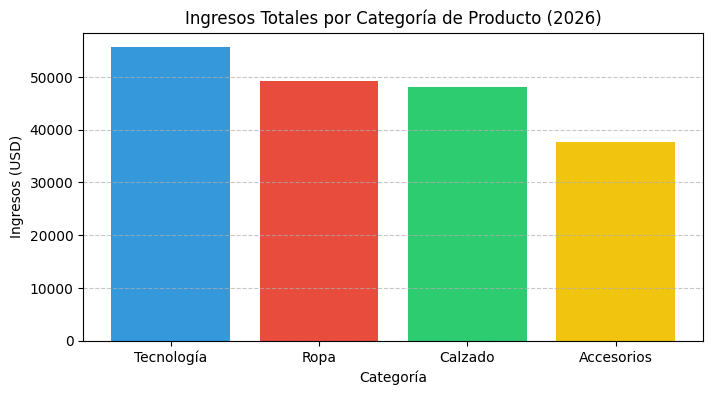

In [ ]:
# 3. Gráfica de barras de ingresos por categoría
plt.figure(figsize=(8, 4))
plt.bar(ventas_por_categoria['categoria'], ventas_por_categoria['ingreso_total'], color=['#3498db', '#e74c3c', '#2ecc71', '#f1c40f'])
plt.title('Ingresos Totales por Categoría de Producto (2026)')
plt.xlabel('Categoría')
plt.ylabel('Ingresos (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()